In [4]:
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

In [3]:
# step - 1: Load Data and Create split

ROLL_N0 = "M26CSA016"

seed_digits = "".join(char for char in ROLL_N0 if char.isdigit())

if not seed_digits:
  raise ValueError("Please Enter Your Roll Number.")

seed = int(seed_digits)
rng = np.random.default_rng(seed)
# print("rng :",rng)

faces = fetch_olivetti_faces()
print(faces.keys())
print(faces.data.shape)
print(faces.images.shape)
print(faces.target.shape)
# df = pd.DataFrame(faces.data)
# df.shape

X = faces.images.reshape(len(faces.images), -1)
y = faces.target

print("X shape : ", X.shape)
print("y shape : ", y.shape)

train_indices = []
val_indices = []
test_indices = []

for identity in np.unique(y):
  identity_indices = np.where(y == identity)[0]
  shuffled_indices = rng.permutation(identity_indices)

  train_indices.extend(shuffled_indices[:6])
  val_indices.extend(shuffled_indices[6:8])
  test_indices.extend(shuffled_indices[8:10])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
test_indices = np.array(test_indices)

np.savez(
    "olivetti_split.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
    seed=seed
)

X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

print("Dataset and split created.")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)






downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
dict_keys(['data', 'images', 'target', 'DESCR'])
(400, 4096)
(400, 64, 64)
(400,)
X shape :  (400, 4096)
y shape :  (400,)
Dataset and split created.
Training: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [4]:
# Try all 15 tree settings

depths = [2,4,8,16, None]
leafs = [1,2,4]

results = []
best_val_accuracy = -1
best_model = None
best_depth = None
best_min_leaf = None

for depth in depths:
  for min_leaf in leafs:

    model = DecisionTreeClassifier(
        max_depth = depth,
        min_samples_leaf = min_leaf,
        random_state = seed
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)
    val_accuracy = model.score(X_val, y_val)

    results.append({
            "max_depth": depth,
            "min_samples_leaf": min_leaf,
            "train_accuracy": train_accuracy,
            "validation_accuracy": val_accuracy
        })

    if val_accuracy > best_val_accuracy:
      best_val_accuracy = val_accuracy
      best_model = model
      best_depth = depth
      best_min_leaf = min_leaf

results_df = pd.DataFrame(results)

print("All 15 Tree Settings : ")
print(results_df.to_string(index=False))

print("\nSelected tree settings:")
print("max_depth:", best_depth)
print("min_samples_leaf:", best_min_leaf)
print("Validation accuracy:", best_val_accuracy)

All 15 Tree Settings : 
 max_depth  min_samples_leaf  train_accuracy  validation_accuracy
       2.0                 1           0.075               0.0625
       2.0                 2           0.075               0.0625
       2.0                 4           0.075               0.0625
       4.0                 1           0.125               0.1125
       4.0                 2           0.125               0.1125
       4.0                 4           0.125               0.1125
       8.0                 1           0.225               0.1875
       8.0                 2           0.225               0.1875
       8.0                 4           0.225               0.1875
      16.0                 1           0.425               0.3625
      16.0                 2           0.425               0.3625
      16.0                 4           0.425               0.3625
       NaN                 1           1.000               0.6250
       NaN                 2           0.975        

In [5]:
# evaluate frozen tree

train_accuracy = best_model.score(X_train, y_train)
val_accuracy = best_model.score(X_val, y_val)
test_accuracy = best_model.score(X_test, y_test)

train_leaf_ids = best_model.apply(X_train)

_, samples_per_leaf = np.unique(
    train_leaf_ids,
    return_counts=True
)

number_of_leaves = len(samples_per_leaf)
mean_samples_per_leaf = np.mean(samples_per_leaf)

fraction_single_sample_leaves = np.mean(
    samples_per_leaf == 1
)

print("\nFINAL BASELINE RESULTS")
print("----------------------")
print("Train accuracy:", train_accuracy)
print("Validation accuracy:", val_accuracy)
print("Test accuracy:", test_accuracy)
print("Number of leaves:", number_of_leaves)
print("Mean samples per leaf:", mean_samples_per_leaf)
print(
    "Fraction of leaves with one training example:",
    fraction_single_sample_leaves
)



FINAL BASELINE RESULTS
----------------------
Train accuracy: 0.975
Validation accuracy: 0.65
Test accuracy: 0.5625
Number of leaves: 40
Mean samples per leaf: 6.0
Fraction of leaves with one training example: 0.0


In [6]:
# --------------------------------------------------
# Q1(b): BAGGING IMPLEMENTED FROM SCRATCH
# --------------------------------------------------

from sklearn.tree import DecisionTreeClassifier
import numpy as np
import pandas as pd


In [7]:
B_values = [1, 5, 10, 25, 50, 100, 200]

n_train = len(X_train)

bootstrap_rng = np.random.default_rng(seed)

bagged_trees = []
bootstrap_indices_list = []
distinct_counts = []

In [8]:
for b in range(200):

  bootstrap_indices = bootstrap_rng.choice(
      n_train,
      size = n_train,
      replace = True
  )

  bootstrap_indices_list.append(bootstrap_indices)
  distinct_counts.append(len(np.unique(bootstrap_indices)))

  X_bootstrap = X_train[bootstrap_indices]
  y_bootstrap = y_train[bootstrap_indices]

  tree = DecisionTreeClassifier(
      max_depth = best_depth,
      min_samples_leaf = best_min_leaf,
      random_state = seed + b
  )

  tree.fit(X_bootstrap, y_bootstrap)
  bagged_trees.append(tree)


print("Trees trained:", len(bagged_trees))
print("Bootstrap indices saved:", len(bootstrap_indices_list))

Trees trained: 200
Bootstrap indices saved: 200


In [9]:
train_predictions = np.array([
    tree.predict(X_train) for tree in bagged_trees
])

val_predictions = np.array([
    tree.predict(X_val) for tree in bagged_trees
])

test_predictions = np.array([
    tree.predict(X_test) for tree in bagged_trees
])

# print(test_predictions)

In [10]:
def majority_vote(predictions):

  final_predictions = []

  for p in predictions.T:

    vote_counts = np.bincount(
        p.astype(int),
        minlength = 40
    )

    final_predictions.append(np.argmax(vote_counts))

  return np.array(final_predictions)

In [11]:
# evaluate diff ensemble sizes

results_b = []

for B in B_values:

  train_pred = majority_vote(train_predictions[:B])
  val_pred = majority_vote(val_predictions[:B])
  test_pred = majority_vote(test_predictions[:B])

  train_accuracy = np.mean(train_pred == y_train)
  val_accuracy = np.mean(val_pred == y_val)
  test_accuracy = np.mean(test_pred == y_test)

  average_distinct = np.mean(distinct_counts[:B])

  results_b.append({
      "B": B,
      "train_accuracy": train_accuracy,
      "validation_accuracy": val_accuracy,
       "test_accuracy": test_accuracy,
      "avg_distinct_examples": average_distinct
  })


results_b_df = pd.DataFrame(results_b)

print("Q1(b): BAGGING RESULTS")
print(results_b_df.to_string(index=False))




Q1(b): BAGGING RESULTS
  B  train_accuracy  validation_accuracy  test_accuracy  avg_distinct_examples
  1        0.725000               0.4250         0.4500                 155.00
  5        0.937500               0.5750         0.5875                 152.20
 10        0.983333               0.7625         0.7125                 151.70
 25        1.000000               0.8125         0.7625                 151.24
 50        1.000000               0.8875         0.9000                 151.04
100        1.000000               0.8750         0.9125                 151.68
200        1.000000               0.8750         0.9125                 152.08


In [12]:
# compare with theoretical expectation

theoretical_distinct = n_train * (
    1 - (1 - 1 / n_train) ** n_train
)

print("\nNumber of original training examples:", n_train)
print("Theoretical expected distinct examples:",
      theoretical_distinct)
print("Theoretical fraction of training set represented:",
      theoretical_distinct / n_train)


Number of original training examples: 240
Theoretical expected distinct examples: 151.8931938460841
Theoretical fraction of training set represented: 0.6328883076920171


In [17]:
# Q(1) - c

import matplotlib.pyplot as plt

results_c = []

oob_masks = []

for bootstrap_indices in bootstrap_indices_list:

  mask = np.ones(n_train, dtype = bool)
  mask[np.unique(bootstrap_indices)] = False
  oob_masks.append(mask)

oob_masks = np.array(oob_masks)
# print(np.array(oob_masks).shape)



(200, 240)


In [27]:
for B in B_values:

  # 1.OUT-OF-BAG (OOB) ACCURACY

  oob_vote_counts = np.zeros((n_train, 40), dtype = int)

  for t in range(B):
    oob_indices = np.where(oob_masks[t])[0]
    oob_labels = train_predictions[t, oob_indices].astype(int)

    oob_vote_counts[oob_indices, oob_labels] += 1

    has_oob_votes = oob_vote_counts.sum(axis=1) > 0

    oob_predictions = np.argmax(oob_vote_counts, axis = 1)

    oob_accuracy = np.mean(oob_predictions[has_oob_votes] == y_train[has_oob_votes])

  # avg pairwise disagreementt

  disagreements = []

  for i in range(B):
    for j in range(i + 1, B):
      disagreement = np.mean(val_predictions[i] != val_predictions[j])
      disagreements.append(disagreement)

  avg_disagreement = (
        np.mean(disagreements) if disagreements else np.nan
    )

  # mean-vote margin

  margins = []

  for image_pred in val_predictions[:B].T:
    vote_counts = np.bincount(
        image_pred.astype(int),
        minlength = 40
    )

    sorted_votes = np.sort(vote_counts)

    winning_fraction = sorted_votes[-1] / B
    runner_up_fraction = sorted_votes[-2] / B

    margins.append(winning_fraction - runner_up_fraction)

  mean_vote_margin = np.mean(margins)

  results_c.append({
     "B": B,
     "OOB_accuracy": oob_accuracy,
     "pairwise_disagreement": avg_disagreement,
     "mean_vote_margin": mean_vote_margin
    })

results_c_df = pd.DataFrame(results_c)

print("Q1(c): ENSEMBLE DIAGNOSTICS")
print(results_c_df.to_string(index=False))


Q1(c): ENSEMBLE DIAGNOSTICS
  B  OOB_accuracy  pairwise_disagreement  mean_vote_margin
  1      0.352941                    NaN          1.000000
  5      0.241860               0.823750          0.212500
 10      0.367089               0.807222          0.232500
 25      0.562500               0.804708          0.243000
 50      0.716667               0.802684          0.257750
100      0.758333               0.803942          0.254375
200      0.770833               0.805903          0.251625


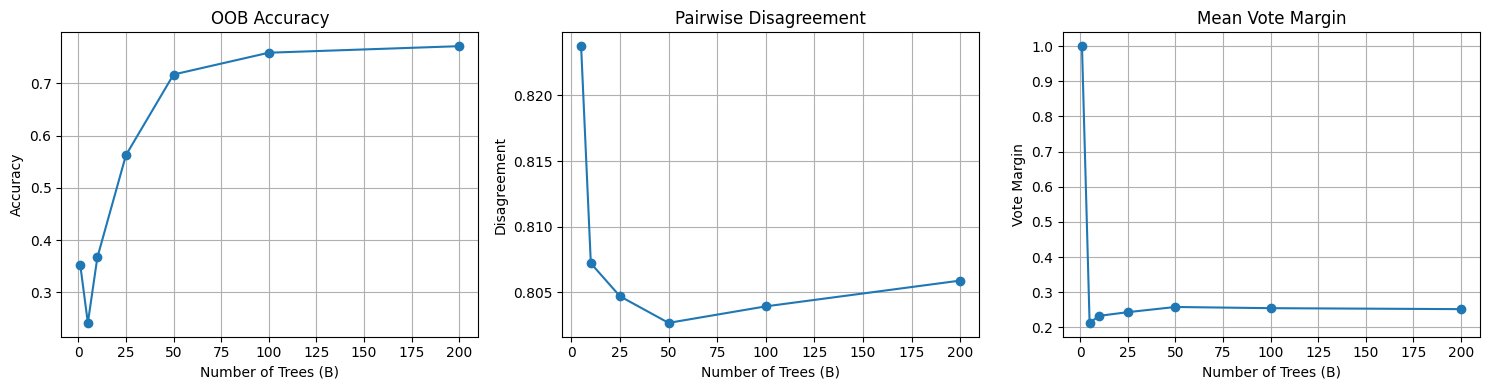

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    results_c_df["B"],
    results_c_df["OOB_accuracy"],
    marker="o"
)
axes[0].set_title("OOB Accuracy")
axes[0].set_xlabel("Number of Trees (B)")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True)

axes[1].plot(
    results_c_df["B"],
    results_c_df["pairwise_disagreement"],
    marker="o"
)
axes[1].set_title("Pairwise Disagreement")
axes[1].set_xlabel("Number of Trees (B)")
axes[1].set_ylabel("Disagreement")
axes[1].grid(True)

axes[2].plot(
    results_c_df["B"],
    results_c_df["mean_vote_margin"],
    marker="o"
)
axes[2].set_title("Mean Vote Margin")
axes[2].set_xlabel("Number of Trees (B)")
axes[2].set_ylabel("Vote Margin")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [29]:
# Q(1).d

import numpy as np
import pandas as pd

# Final ensemble size selected using validation accuracy
B_final = 50
final_trees = bagged_trees[:B_final]

# ----------------------------------
# CREATE CLEAN AND MASKED TEST SETS
# ----------------------------------

X_test_clean = X_test.copy()

X_test_masked_images = X_test.reshape(-1, 64, 64).copy()
X_test_masked_images[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked_images.reshape(len(X_test), -1)

# ----------------------------------
# PREDICTION AND CONFIDENCE FUNCTION
# ----------------------------------

def evaluate_models(X_eval, y_true):
    # Single decision tree
    tree_predictions = best_model.predict(X_eval)
    tree_probabilities = best_model.predict_proba(X_eval)
    tree_confidence = np.max(tree_probabilities, axis=1)

    # Bagged model: count votes from 50 trees
    bagging_votes = np.array([
        tree.predict(X_eval) for tree in final_trees
    ])

    bagging_predictions = []
    bagging_confidence = []
    all_vote_counts = []

    for image_predictions in bagging_votes.T:
        vote_counts = np.bincount(image_predictions.astype(int),
                                  minlength=40)

        bagging_predictions.append(np.argmax(vote_counts))
        bagging_confidence.append(np.max(vote_counts) / B_final)
        all_vote_counts.append(vote_counts)

    bagging_predictions = np.array(bagging_predictions)
    bagging_confidence = np.array(bagging_confidence)
    all_vote_counts = np.array(all_vote_counts)

    results = {
        "Tree accuracy": np.mean(tree_predictions == y_true),
        "Tree mean confidence": np.mean(tree_confidence),
        "Bagging accuracy": np.mean(bagging_predictions == y_true),
        "Bagging mean confidence": np.mean(bagging_confidence)
    }

    return (results, tree_predictions, tree_confidence,
            bagging_predictions, bagging_confidence, all_vote_counts)


# Evaluate both test sets
clean_result = evaluate_models(X_test_clean, y_test)
masked_result = evaluate_models(X_test_masked, y_test)

comparison_df = pd.DataFrame([
    {"Test set": "Clean", **clean_result[0]},
    {"Test set": "Masked", **masked_result[0]}
])

print("Q1(d): ACCURACY AND MEAN PREDICTION CONFIDENCE")
print(comparison_df.to_string(index=False))

Q1(d): ACCURACY AND MEAN PREDICTION CONFIDENCE
Test set  Tree accuracy  Tree mean confidence  Bagging accuracy  Bagging mean confidence
   Clean         0.5625              0.981548            0.9000                  0.39100
  Masked         0.2750              1.000000            0.7375                  0.29225


In [30]:
# Results on the clean test set
(_, tree_pred, tree_conf,
 bag_pred, bag_conf, vote_counts) = clean_result

# Bagging corrects the tree
corrected = np.where(
    (tree_pred != y_test) & (bag_pred == y_test)
)[0]

# Both models are wrong
both_wrong = np.where(
    (tree_pred != y_test) & (bag_pred != y_test)
)[0]


def show_cases(indices, title):
    print("\n" + title)
    print("=" * len(title))

    if len(indices) == 0:
        print("No examples found.")
        return

    if len(indices) < 2:
        print("Only", len(indices), "example(s) found.")

    for i in indices[:2]:
        # Show only classes receiving at least one vote
        votes = {
            class_id: int(vote_counts[i, class_id])
            for class_id in range(40)
            if vote_counts[i, class_id] > 0
        }

        print(f"\nTest-set position: {i}")
        print(f"Original dataset image index: {test_indices[i]}")
        print(f"Actual identity: {y_test[i]}")
        print(f"Tree prediction: {tree_pred[i]}")
        print(f"Tree confidence: {tree_conf[i]:.3f}")
        print(f"Bagging prediction: {bag_pred[i]}")
        print(f"Bagging confidence: {bag_conf[i]:.3f}")
        print(f"Bagging vote counts: {votes}")


show_cases(corrected, "TWO CASES WHERE BAGGING CORRECTS THE TREE")
show_cases(both_wrong, "TWO CASES WHERE BOTH MODELS ARE WRONG")


TWO CASES WHERE BAGGING CORRECTS THE TREE

Test-set position: 0
Original dataset image index: 3
Actual identity: 0
Tree prediction: 11
Tree confidence: 1.000
Bagging prediction: 0
Bagging confidence: 0.400
Bagging vote counts: {0: 20, 2: 2, 3: 3, 6: 1, 9: 1, 11: 4, 12: 1, 16: 2, 17: 1, 20: 2, 22: 1, 23: 3, 27: 2, 28: 2, 30: 1, 35: 2, 37: 1, 39: 1}

Test-set position: 1
Original dataset image index: 2
Actual identity: 0
Tree prediction: 1
Tree confidence: 1.000
Bagging prediction: 0
Bagging confidence: 0.340
Bagging vote counts: {0: 17, 1: 1, 2: 1, 3: 2, 4: 1, 6: 1, 7: 5, 9: 2, 10: 2, 13: 1, 15: 10, 17: 2, 24: 1, 26: 2, 37: 1, 39: 1}

TWO CASES WHERE BOTH MODELS ARE WRONG

Test-set position: 7
Original dataset image index: 32
Actual identity: 3
Tree prediction: 35
Tree confidence: 1.000
Bagging prediction: 4
Bagging confidence: 0.180
Bagging vote counts: {0: 1, 1: 4, 3: 5, 4: 9, 5: 1, 7: 1, 11: 1, 12: 2, 14: 2, 18: 1, 19: 1, 20: 2, 21: 1, 23: 1, 25: 1, 28: 2, 30: 3, 32: 1, 35: 4, 36: 1

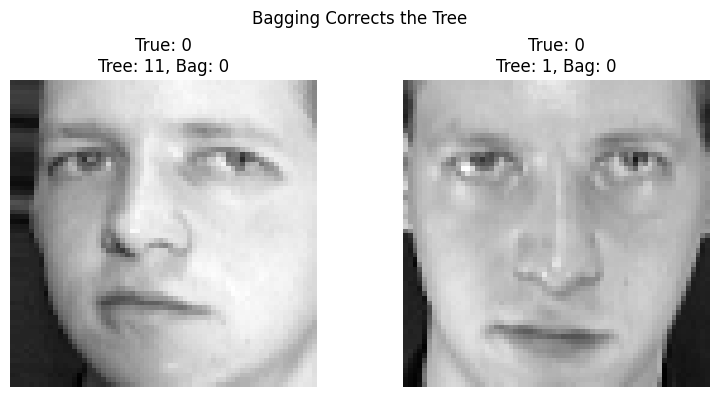

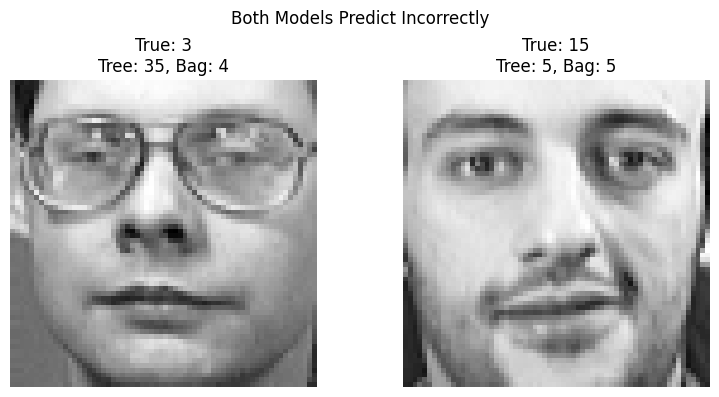

In [31]:
import matplotlib.pyplot as plt

def display_cases(indices, title):
    selected = indices[:2]

    if len(selected) == 0:
        print("No examples available for:", title)
        return

    fig, axes = plt.subplots(1, len(selected), figsize=(4 * len(selected), 4))
    axes = np.atleast_1d(axes)

    for ax, i in zip(axes, selected):
        ax.imshow(X_test_clean[i].reshape(64, 64), cmap="gray")
        ax.set_title(
            f"True: {y_test[i]}\n"
            f"Tree: {tree_pred[i]}, Bag: {bag_pred[i]}"
        )
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


display_cases(corrected, "Bagging Corrects the Tree")
display_cases(both_wrong, "Both Models Predict Incorrectly")